In [70]:
import pandas as pd

df = pd.read_csv("data_clean.csv")
df_original = pd.read_csv("data.csv")

In [71]:
df.columns

Index(['Age ', 'BMI', 'Tumor size', 'Tumor size.1', 'Tumor size.2',
       'Last BMI on file', 'Length of followup',
       'Pre-op visual impairment (y/n) - symptomatic complaint of visual loss',
       'Pre-op hydrocephalus (y/n)', 'Pre-op intacranial pressure symptoms',
       'Pre-op headache', 'Pre-op endocrine changes (y/n)',
       'Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional',
       'Intraventricular extension', 'CSF leak', 'Mortality Y/N',
       'Prior operation', 'recurring tumor?',
       'Recurrence after this operation', 'Shunt (y/n) ', 'Transient DI',
       'Permanent DI',
       'DDAVP (y/n) - most patients get periop, can do time frame (in hospital vs 1 mo vs 1 yr postop)',
       'DDAVP outside of hospital', 'DDAVP ≥1 year', 'Post-op new panhypopit',
       'Other vascular complication (need to specify)',
       'Hemorrhage or hemorrhagic stroke', 'Ischemic Stroke',
       'Other intracranial infection', 'Non-intracranial infectio

In [84]:
import pandas as pd
from pycaret.classification import setup, compare_models, tune_model, pull
from sklearn.exceptions import NotFittedError

# Load your raw dataset
df_original = pd.read_csv("data.csv")

# ---- Feature groups (for convenience) ----
preop_basic = [
    "Age ", "BMI", "Tumor size", "Tumor size.1", "Tumor size.2", "Tumor volume",
    "Last BMI on file",
    "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss",
    "Pre-op hydrocephalus (y/n)", "Pre-op intacranial pressure symptoms",
    "Pre-op headache", "Pre-op endocrine changes (y/n)",
    "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional",
    "Intraventricular extension"
]

intraop_basic = [
    "Surgical Approach",                 # raw categorical in df_original
    "Solid, cystic, mixed",              # raw categorical in df_original
    "Resection outcome (total, subtotal, partial)"
]

location_histology = [
    "Location (purely intrasellar, suprasellar/sellar, suprasellar/sellar with pseudoventricular extension, suprasellar/sellar with intraventricular extension, purely intraventricular)",
    "Tumor (Adamantinomatous, papillary)",
    "BRAF+"
]

# ---- Build 15 experiments (targets + feature sets) ----
experiments = [
    # Post-op complications
    {"target": "Permanent DI",
     "features": preop_basic + ["Surgical Approach", "Resection outcome (total, subtotal, partial)"]},




    # Composite endpoints (you can create these columns beforehand if desired)
    # Example creation idea (run before the loop):
    # df_original["Any complication"] = (
    #     (df_original["CSF leak"]==1) | (df_original["Transient DI"]==1) |
    #     (df_original["Permanent DI"]==1) | (df_original["Other vascular complication (need to specify)"]==1) |
    #     (df_original["Hemorrhage or hemorrhagic stroke"]==1) | (df_original["Ischemic Stroke"]==1) |
    #     (df_original["Other intracranial infection"]==1) | (df_original["Non-intracranial infection"]==1) |
    #     (df_original["Meningitis"]==1)
    # ).astype(int)

    # If you already created it, uncomment the experiment below:
    # {"target": "Any complication",
    #  "features": preop_basic + intraop_basic + location_histology},

    # Visual outcome (binary version you can precompute; multi-class needs classification setup too)
    # df_original["VisualImproved"] = (df_original[
    #   "Post-op visual improvement/stable/worse (subjective); should add something specific about visual fields if any patients have; add about visual acuity"
    # ].astype(str).str.lower().str.contains("improv")).astype(int)

    # {"target": "VisualImproved",
    #  "features": preop_basic + ["Surgical Approach"] + location_histology},

    # Two more variations to reach 15 now (without needing new columns):

]

# ---- Utility: safe compare + tune ----
def run_experiment(df, target, features, metric="AUC"):
    # Keep only columns that exist (avoid KeyError if some columns are missing)
    cols = [c for c in features + [target] if c in df.columns]
    if target not in cols:
        print(f"  [skip] Target column '{target}' not found.")
        return None, None

    # Drop rows where target is missing
    data = df[cols].copy()
    data = data[~data[target].isna()]
    if data[target].nunique() < 2:
        print(f"  [skip] Target '{target}' has <2 classes after dropping NaNs.")
        return None, None

    # PyCaret setup
    clf_setup = setup(
        data=data,
        target=target,
        session_id=42,
        fold=3,                      # safer with rare events
        fold_strategy="stratifiedkfold",
        fix_imbalance=True,          # handle class imbalance
        use_gpu=False,
        verbose=False
    )

    # Compare and enforce single estimator
    best_model = compare_models(sort=metric, n_select=1)
    # Guard: sometimes returns list
    if isinstance(best_model, list):
        best_model = best_model[0]

    if not hasattr(best_model, "fit"):
        print("  [skip] No valid estimator returned by compare_models.")
        return None, None

    # Tune
    try:
        tuned = tune_model(best_model, optimize=metric)
    except Exception as e:
        print(f"  [warn] tune_model failed for '{target}': {e}")
        tuned = best_model

    leaderboard = pull()
    return tuned, leaderboard

# ---- Run all experiments ----
all_leaderboards = {}
for exp in experiments:
    print(f"\n=== Running target: {exp['target']} ===")
    try:
        tuned, leaderboard = run_experiment(df_original, exp["target"], exp["features"], metric="AUC")
        if leaderboard is not None:
            all_leaderboards[exp["target"]] = leaderboard.copy()
            # Show the top few rows for quick inspection
            print(leaderboard.head())
    except Exception as e:
        print(f"  [error] {exp['target']}: {e}")

# Optionally, concatenate and save all results
if all_leaderboards:
    lb_all = pd.concat({k: v for k, v in all_leaderboards.items()}, names=["Target", "Row"]).reset_index(level=0)
    lb_all.to_csv("automl_leaderboards.csv", index=False)
    print("\nSaved: automl_leaderboards.csv")



=== Running target: Permanent DI ===


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
ridge,Ridge Classifier,0.7491,0.7019,0.7685,0.8333,0.7990,0.4656,0.4700,0.0367
gbc,Gradient Boosting Classifier,0.6758,0.6991,0.8056,0.7222,0.7616,0.2533,0.2576,0.0733
et,Extra Trees Classifier,0.6996,0.6949,0.7685,0.7731,0.7691,0.3424,0.3455,0.0867
lda,Linear Discriminant Analysis,0.6245,0.6824,0.5741,0.7857,0.6627,0.2575,0.2759,0.0367
lr,Logistic Regression,0.7253,0.6759,0.7639,0.7937,0.7778,0.4112,0.4121,0.0467
xgboost,Extreme Gradient Boosting,0.6777,0.6676,0.7639,0.7465,0.7519,0.2771,0.2775,0.3867
nb,Naive Bayes,0.5018,0.6630,0.3472,0.7389,0.4683,0.1073,0.1316,0.0433
dt,Decision Tree Classifier,0.7271,0.6565,0.8796,0.7449,0.8040,0.3444,0.3704,0.0400
rf,Random Forest Classifier,0.6777,0.6102,0.8472,0.7121,0.7733,0.2303,0.2392,0.1133
catboost,CatBoost Classifier,0.7051,0.5676,0.8843,0.7264,0.7967,0.2726,0.2787,1.0833


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6667,0.6667,0.8571,0.7500,0.4286,0.4472
1,0.6923,0.6667,0.6667,0.8571,0.7500,0.3659,0.3858
2,0.7692,0.7250,0.7500,0.8571,0.8000,0.5301,0.5367
Mean,0.7253,0.6861,0.6944,0.8571,0.7667,0.4415,0.4566
Std,0.0324,0.0275,0.0393,0.0000,0.0236,0.0677,0.0620


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).
      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.6667  0.6667  0.8571  0.7500  0.4286  0.4472
1       0.6923  0.6667  0.6667  0.8571  0.7500  0.3659  0.3858
2       0.7692  0.7250  0.7500  0.8571  0.8000  0.5301  0.5367
Mean    0.7253  0.6861  0.6944  0.8571  0.7667  0.4415  0.4566
Std     0.0324  0.0275  0.0393  0.0000  0.0236  0.0677  0.0620

Saved: automl_leaderboards.csv


In [73]:
import pandas as pd
from pycaret.classification import setup, create_model, tune_model, finalize_model, save_model, predict_model, pull

# 1) Load raw data
df_original = pd.read_csv("data.csv")

# 2) Define features for Permanent DI (pre-op + intra-op you chose)
features_permdi = [
    "Age ", "BMI", "Tumor size", "Tumor size.1", "Tumor size.2", "Tumor volume",
    "Last BMI on file",
    "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss",
    "Pre-op hydrocephalus (y/n)", "Pre-op intacranial pressure symptoms",
    "Pre-op headache", "Pre-op endocrine changes (y/n)",
    "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional",
    "Intraventricular extension",
    "Surgical Approach", "Resection outcome (total, subtotal, partial)"
]
target = "Permanent DI"

# 3) Keep only rows with target present
cols = [c for c in features_permdi + [target] if c in df_original.columns]
data = df_original[cols].dropna(subset=[target]).copy()

# 4) Pick a safe number of folds (avoid empty-class folds)
vc = data[target].value_counts()
minority = int(vc.min())
folds = max(2, min(3, minority))  # 2–3 folds depending on minority size

# 5) Setup (PyCaret will encode categoricals & impute internally)
_ = setup(
    data=data,
    target=target,
    session_id=42,
    fold=folds,
    fold_strategy="stratifiedkfold",
    fix_imbalance=True,    # helps with rare outcomes
    use_gpu=False,
    verbose=False
)

# 6) Train Ridge, then tune it (optimize F1 for class imbalance)
ridge = create_model("ridge")
ridge_tuned = tune_model(ridge, optimize="F1")

# (optional) Inspect CV leaderboard for tuned ridge
lb = pull()
print(lb.head())

# 7) Finalize on the full dataset (locks preprocessing + tuned params)
ridge_final = finalize_model(ridge_tuned)

# 8) Save the whole pipeline (preprocessing + model)
save_model(ridge_final, "permdi_ridge_v1")

# 9) (optional) Get CV/holdout predictions for sanity check
preds = predict_model(ridge_final)
print(preds.head())


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7857,0.6889,0.7778,0.8750,0.8235,0.5532,0.5594
1,0.7692,0.6667,0.7778,0.8750,0.8235,0.4935,0.5007
2,0.6923,0.7500,0.7500,0.7500,0.7500,0.3500,0.3500
Mean,0.7491,0.7019,0.7685,0.8333,0.7990,0.4656,0.4700
Std,0.0407,0.0352,0.0131,0.0589,0.0347,0.0853,0.0882


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6667,0.6667,0.8571,0.7500,0.4286,0.4472
1,0.6923,0.6667,0.6667,0.8571,0.7500,0.3659,0.3858
2,0.7692,0.7250,0.7500,0.8571,0.8000,0.5301,0.5367
Mean,0.7253,0.6861,0.6944,0.8571,0.7667,0.4415,0.4566
Std,0.0324,0.0275,0.0393,0.0000,0.0236,0.0677,0.0620


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).
      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.6667  0.6667  0.8571  0.7500  0.4286  0.4472
1       0.6923  0.6667  0.6667  0.8571  0.7500  0.3659  0.3858
2       0.7692  0.7250  0.7500  0.8571  0.8000  0.5301  0.5367
Mean    0.7253  0.6861  0.6944  0.8571  0.7667  0.4415  0.4566
Std     0.0324  0.0275  0.0393  0.0000  0.0236  0.0677  0.0620
Transformation Pipeline and Model Successfully Saved


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Ridge Classifier,0.8889,0.9167,0.8333,1.0000,0.9091,0.7692,0.7906


    Age         BMI  Tumor size  Tumor size.1  Tumor size.2  Tumor volume  \
32    65  26.040001         1.4           1.8           1.9      2.506989   
33    60  32.689999         4.1           3.0           2.0     12.880519   
14    64  28.620001         3.4           2.2           1.9      7.441380   
26    26  21.799999         3.7           4.1           2.8     22.240362   
44    73  21.549999         1.2           1.1           1.5      1.036725   

    Last BMI on file  \
32         29.100000   
33         33.900002   
14         29.549999   
26         21.600000   
44         20.600000   

    Pre-op visual impairment (y/n) - symptomatic complaint of visual loss  \
32                                                1.0                       
33                                                1.0                       
14                                                0.0                       
26                                                1.0                       
44     

In [74]:
from sklearn.metrics import classification_report
from pycaret.classification import get_config

X_train = get_config("X_train")
y_train = get_config("y_train")
preds = ridge_final.predict(X_train)

print(classification_report(y_train, preds, digits=3))


              precision    recall  f1-score   support

         0.0      0.667     0.714     0.690        14
         1.0      0.840     0.808     0.824        26

    accuracy                          0.775        40
   macro avg      0.753     0.761     0.757        40
weighted avg      0.779     0.775     0.777        40



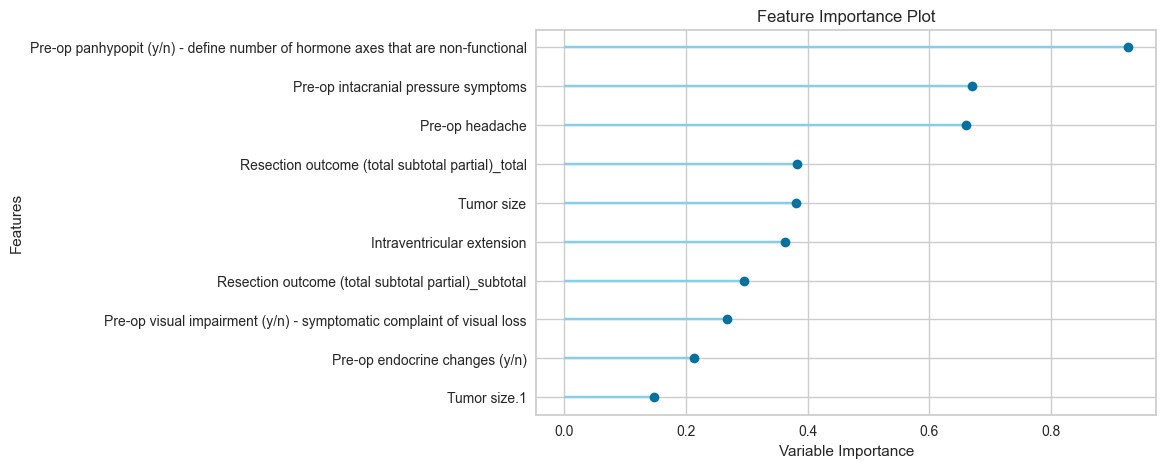

In [75]:
from pycaret.classification import plot_model, interpret_model

# Global feature importance
plot_model(ridge_final, plot="feature")


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7857,0.6889,0.7778,0.8750,0.8235,0.5532,0.5594
1,0.7692,0.6667,0.7778,0.8750,0.8235,0.4935,0.5007
2,0.6923,0.7500,0.7500,0.7500,0.7500,0.3500,0.3500
Mean,0.7491,0.7019,0.7685,0.8333,0.7990,0.4656,0.4700
Std,0.0407,0.0352,0.0131,0.0589,0.0347,0.0853,0.0882


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.5000,0.5111,0.7778,0.5833,0.6667,-0.2564,-0.3043
1,0.8462,0.6667,1.0000,0.8182,0.9000,0.5806,0.6396
2,0.7692,0.5250,0.8750,0.7778,0.8235,0.4935,0.5007
Mean,0.7051,0.5676,0.8843,0.7264,0.7967,0.2726,0.2787
Std,0.1484,0.0703,0.0910,0.1025,0.0971,0.3757,0.4161


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.4778,0.8889,0.6667,0.7619,0.1026,0.1217
1,0.8462,0.7917,1.0000,0.8182,0.9000,0.5806,0.6396
2,0.7692,0.6375,1.0000,0.7273,0.8421,0.4507,0.5394
Mean,0.7527,0.6356,0.9630,0.7374,0.8347,0.3780,0.4336
Std,0.0838,0.1282,0.0524,0.0623,0.0566,0.2018,0.2243


Fitting 3 folds for each of 10 candidates, totalling 30 fits


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.7333,0.8889,0.7273,0.8000,0.3171,0.3373
1,0.7692,0.6806,0.7778,0.8750,0.8235,0.4935,0.5007
2,0.6923,0.6750,0.7500,0.7500,0.7500,0.3500,0.3500
Mean,0.7253,0.6963,0.8056,0.7841,0.7912,0.3869,0.3960
Std,0.0324,0.0263,0.0600,0.0649,0.0307,0.0766,0.0742


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7857,0.7778,0.8889,0.8000,0.8421,0.5116,0.5185
1,0.7692,0.8333,0.8889,0.8000,0.8421,0.4179,0.4260
2,0.6923,0.7000,0.7500,0.7500,0.7500,0.3500,0.3500
Mean,0.7491,0.7704,0.8426,0.7833,0.8114,0.4265,0.4315
Std,0.0407,0.0547,0.0655,0.0236,0.0434,0.0663,0.0689


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7857  0.7778  0.8889  0.8000  0.8421  0.5116  0.5185
1       0.7692  0.8333  0.8889  0.8000  0.8421  0.4179  0.4260
2       0.6923  0.7000  0.7500  0.7500  0.7500  0.3500  0.3500
Mean    0.7491  0.7704  0.8426  0.7833  0.8114  0.4265  0.4315
Std     0.0407  0.0547  0.0655  0.0236  0.0434  0.0663  0.0689


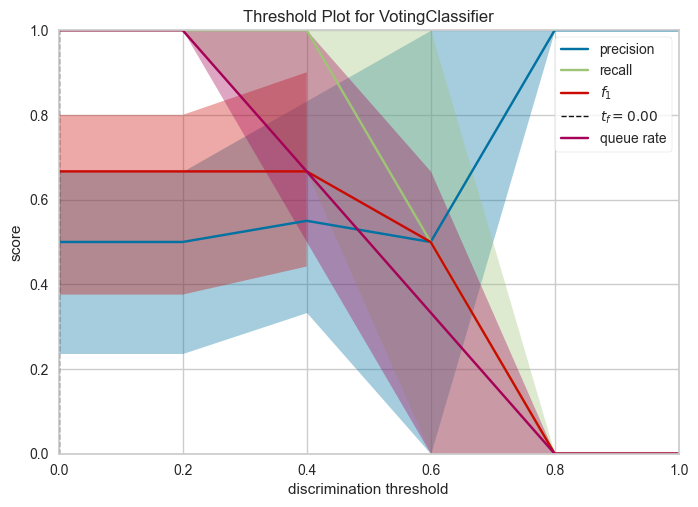

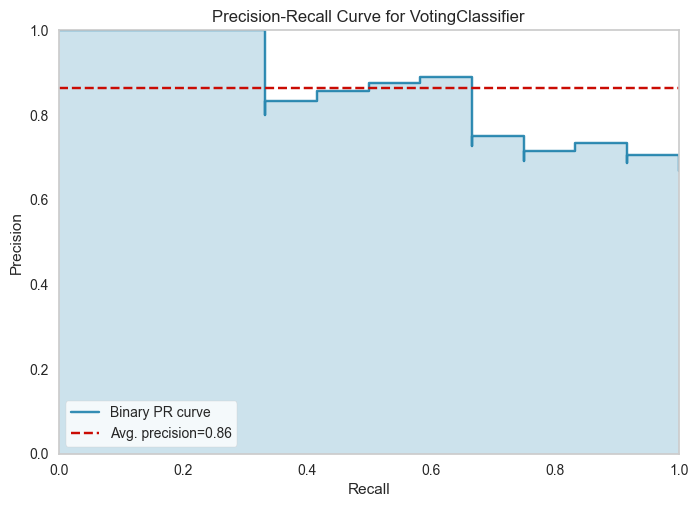

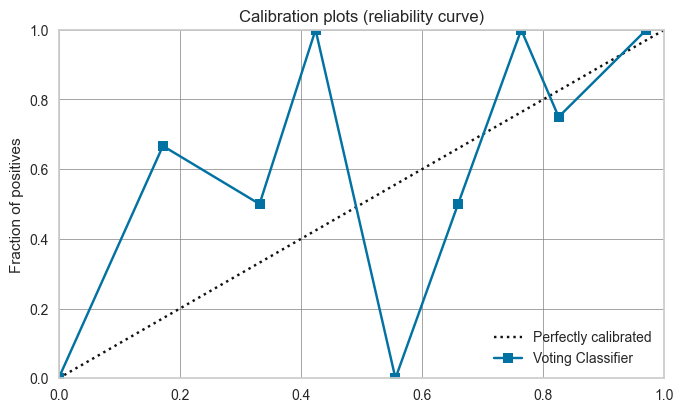

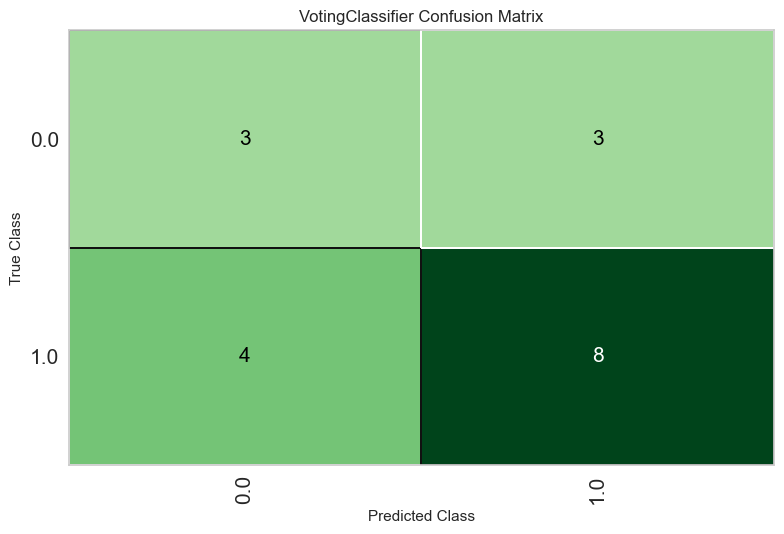

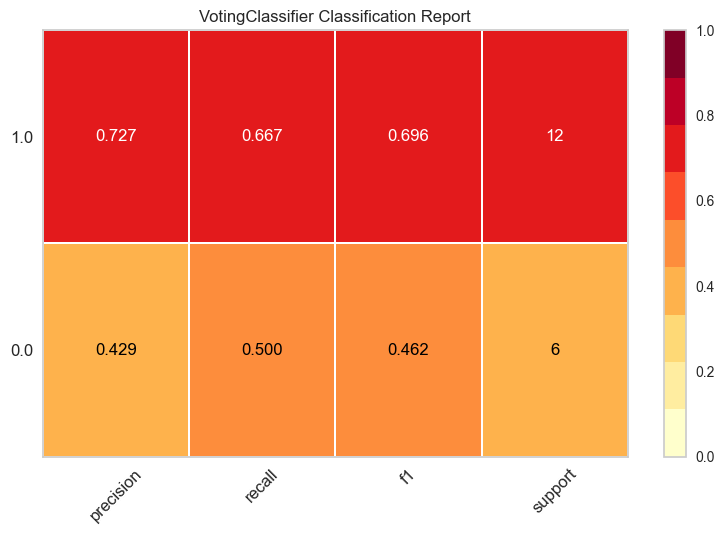

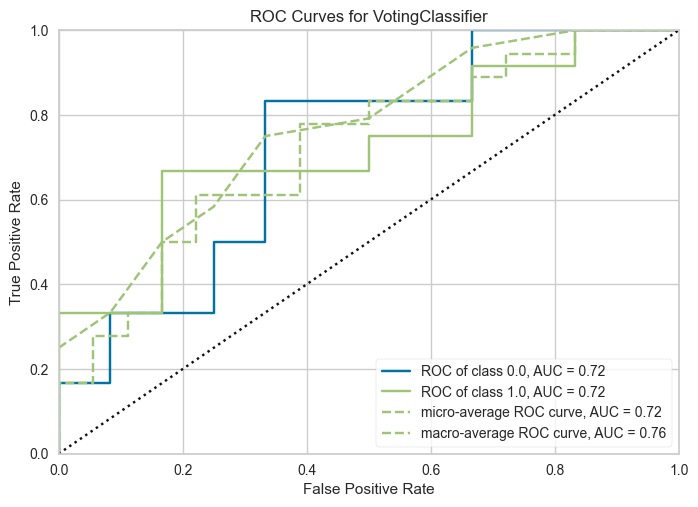

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Age ', 'BMI', 'Tumor size',
                                              'Tumor size.1', 'Tumor size.2',
                                              'Tumor volume', 'Last BMI on file',
                                              'Pre-op visual impairment (y/n) - '
                                              'symptomatic complaint of visual '
                                              'loss',
                                              'Pre-op hydrocephalus (y/n)',
                                              'Pre-op intacranial pressure '
                                              'symptoms',
                                              'Pre-op headache',
                                              'Pre-op endoc...
                                                                       estimato

In [ ]:
import pandas as pd
from pycaret.classification import (
    setup, create_model, tune_model, calibrate_model,
    blend_models, compare_models, finalize_model, save_model, pull
)

# --- Build the modeling table exactly as before ---
df = pd.read_csv("data.csv")
features_permdi = [
    "Age ", "BMI", "Tumor size", "Tumor size.1", "Tumor size.2", "Tumor volume",
    "Last BMI on file",
    "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss",
    "Pre-op hydrocephalus (y/n)", "Pre-op intacranial pressure symptoms",
    "Pre-op headache", "Pre-op endocrine changes (y/n)",
    "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional",
    "Intraventricular extension",
    "Surgical Approach", "Resection outcome (total, subtotal, partial)"
]
target = "Permanent DI"

data = df[features_permdi + [target]].dropna(subset=[target]).copy()
folds = max(2, min(3, int(data[target].value_counts().min())))

_ = setup(
    data=data,
    target=target,
    session_id=42,
    fold=folds,
    fold_strategy="stratifiedkfold",
    fix_imbalance=True,
    verbose=False
)

# Base learners
ridge = create_model("ridge")                     # strong precision
cat   = create_model("catboost")                  # strong recall
# Optional tuning (often helps catboost a bit)
cat_t = tune_model(cat, optimize="F1")

# Calibrate ridge (gives reliable proba for blending / ROC)
ridge_cal = calibrate_model(ridge, method="isotonic")  # or "sigmoid"

# Blend (soft vote on calibrated probabilities)
blend = blend_models(
    estimator_list=[ridge_cal, cat_t],
    method="soft",          # uses probabilities
    optimize="AUC"          # or "F1" if you care more about positives
)

# See CV metrics of the blend
print(pull().head())

# Threshold tuning (pick operating point)
from pycaret.classification import plot_model
plot_model(blend, plot="threshold")       # interactively pick threshold
plot_model(blend, plot="pr")              # PR curve is informative for rare events
plot_model(blend, plot="calibration")     # check probability calibration
plot_model(blend, plot="auc")

# Finalize & save
blend_final = finalize_model(blend)
save_model(blend_final, "permdi_blend_ridge_cat_v1")


In [79]:
print("\n=== Ridge (base) ===")
ridge = create_model("ridge")
print(pull())

print("\n=== CatBoost (base) ===")
cat = create_model("catboost")
print(pull())

print("\n=== CatBoost (tuned) ===")
cat_t = tune_model(cat, optimize="F1")
print(pull())

print("\n=== Ridge Calibrated (isotonic) ===")
ridge_cal = calibrate_model(ridge, method="isotonic")
print(pull())

print("\n=== Blend (RidgeCal + CatBoost) ===")
blend = blend_models([ridge_cal, cat_t], method="soft", optimize="AUC")
print(pull())



=== Ridge (base) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7857,0.6889,0.7778,0.8750,0.8235,0.5532,0.5594
1,0.7692,0.6667,0.7778,0.8750,0.8235,0.4935,0.5007
2,0.6923,0.7500,0.7500,0.7500,0.7500,0.3500,0.3500
Mean,0.7491,0.7019,0.7685,0.8333,0.7990,0.4656,0.4700
Std,0.0407,0.0352,0.0131,0.0589,0.0347,0.0853,0.0882


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7857  0.6889  0.7778  0.8750  0.8235  0.5532  0.5594
1       0.7692  0.6667  0.7778  0.8750  0.8235  0.4935  0.5007
2       0.6923  0.7500  0.7500  0.7500  0.7500  0.3500  0.3500
Mean    0.7491  0.7019  0.7685  0.8333  0.7990  0.4656  0.4700
Std     0.0407  0.0352  0.0131  0.0589  0.0347  0.0853  0.0882

=== CatBoost (base) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.5000,0.5111,0.7778,0.5833,0.6667,-0.2564,-0.3043
1,0.8462,0.6667,1.0000,0.8182,0.9000,0.5806,0.6396
2,0.7692,0.5250,0.8750,0.7778,0.8235,0.4935,0.5007
Mean,0.7051,0.5676,0.8843,0.7264,0.7967,0.2726,0.2787
Std,0.1484,0.0703,0.0910,0.1025,0.0971,0.3757,0.4161


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.5000  0.5111  0.7778  0.5833  0.6667 -0.2564 -0.3043
1       0.8462  0.6667  1.0000  0.8182  0.9000  0.5806  0.6396
2       0.7692  0.5250  0.8750  0.7778  0.8235  0.4935  0.5007
Mean    0.7051  0.5676  0.8843  0.7264  0.7967  0.2726  0.2787
Std     0.1484  0.0703  0.0910  0.1025  0.0971  0.3757  0.4161

=== CatBoost (tuned) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.4778,0.8889,0.6667,0.7619,0.1026,0.1217
1,0.8462,0.7917,1.0000,0.8182,0.9000,0.5806,0.6396
2,0.7692,0.6375,1.0000,0.7273,0.8421,0.4507,0.5394
Mean,0.7527,0.6356,0.9630,0.7374,0.8347,0.3780,0.4336
Std,0.0838,0.1282,0.0524,0.0623,0.0566,0.2018,0.2243


Fitting 3 folds for each of 10 candidates, totalling 30 fits
      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.6429  0.4778  0.8889  0.6667  0.7619  0.1026  0.1217
1       0.8462  0.7917  1.0000  0.8182  0.9000  0.5806  0.6396
2       0.7692  0.6375  1.0000  0.7273  0.8421  0.4507  0.5394
Mean    0.7527  0.6356  0.9630  0.7374  0.8347  0.3780  0.4336
Std     0.0838  0.1282  0.0524  0.0623  0.0566  0.2018  0.2243

=== Ridge Calibrated (isotonic) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.7333,0.8889,0.7273,0.8000,0.3171,0.3373
1,0.7692,0.6806,0.7778,0.8750,0.8235,0.4935,0.5007
2,0.6923,0.6750,0.7500,0.7500,0.7500,0.3500,0.3500
Mean,0.7253,0.6963,0.8056,0.7841,0.7912,0.3869,0.3960
Std,0.0324,0.0263,0.0600,0.0649,0.0307,0.0766,0.0742


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.7333  0.8889  0.7273  0.8000  0.3171  0.3373
1       0.7692  0.6806  0.7778  0.8750  0.8235  0.4935  0.5007
2       0.6923  0.6750  0.7500  0.7500  0.7500  0.3500  0.3500
Mean    0.7253  0.6963  0.8056  0.7841  0.7912  0.3869  0.3960
Std     0.0324  0.0263  0.0600  0.0649  0.0307  0.0766  0.0742

=== Blend (RidgeCal + CatBoost) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7857,0.7778,0.8889,0.8000,0.8421,0.5116,0.5185
1,0.7692,0.8333,0.8889,0.8000,0.8421,0.4179,0.4260
2,0.6923,0.7000,0.7500,0.7500,0.7500,0.3500,0.3500
Mean,0.7491,0.7704,0.8426,0.7833,0.8114,0.4265,0.4315
Std,0.0407,0.0547,0.0655,0.0236,0.0434,0.0663,0.0689


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7857  0.7778  0.8889  0.8000  0.8421  0.5116  0.5185
1       0.7692  0.8333  0.8889  0.8000  0.8421  0.4179  0.4260
2       0.6923  0.7000  0.7500  0.7500  0.7500  0.3500  0.3500
Mean    0.7491  0.7704  0.8426  0.7833  0.8114  0.4265  0.4315
Std     0.0407  0.0547  0.0655  0.0236  0.0434  0.0663  0.0689


In [81]:
from pycaret.classification import stack_models, create_model

# (continue from the same setup; reuse ridge_cal and cat_t)
rf   = create_model("rf")
xgb  = create_model("xgboost")

stack = stack_models(
    estimator_list=[ridge_cal, cat_t, rf, xgb],
    meta_model=create_model("lr"),   # meta learner
    optimize="AUC"                   # or "F1"
)

print(pull().head())
stack_final = finalize_model(stack)
save_model(stack_final, "permdi_stack_v1")


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.5714,0.5556,0.7778,0.6364,0.7000,-0.0244,-0.0259
1,0.7692,0.7500,0.8889,0.8000,0.8421,0.4179,0.4260
2,0.6923,0.5250,0.8750,0.7000,0.7778,0.2973,0.3175
Mean,0.6777,0.6102,0.8472,0.7121,0.7733,0.2303,0.2392
Std,0.0814,0.0996,0.0494,0.0674,0.0581,0.1867,0.1926


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.5714,0.5778,0.7778,0.6364,0.7000,-0.0244,-0.0259
1,0.8462,0.7500,0.8889,0.8889,0.8889,0.6389,0.6389
2,0.6154,0.6750,0.6250,0.7143,0.6667,0.2169,0.2196
Mean,0.6777,0.6676,0.7639,0.7465,0.7519,0.2771,0.2775
Std,0.1205,0.0705,0.1082,0.1056,0.0979,0.2741,0.2745


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.7111,0.7778,0.7778,0.7778,0.3778,0.3778
1,0.8462,0.6667,0.8889,0.8889,0.8889,0.6389,0.6389
2,0.6154,0.6500,0.6250,0.7143,0.6667,0.2169,0.2196
Mean,0.7253,0.6759,0.7639,0.7937,0.7778,0.4112,0.4121
Std,0.0945,0.0258,0.1082,0.0722,0.0907,0.1739,0.1729


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.7111,0.8889,0.7273,0.8000,0.3171,0.3373
1,0.8462,0.7778,0.8889,0.8889,0.8889,0.6389,0.6389
2,0.5385,0.6500,0.5000,0.6667,0.5714,0.0930,0.0976
Mean,0.6996,0.7130,0.7593,0.7609,0.7534,0.3497,0.3579
Std,0.1260,0.0522,0.1833,0.0938,0.1337,0.2240,0.2215


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.7111  0.8889  0.7273  0.8000  0.3171  0.3373
1       0.8462  0.7778  0.8889  0.8889  0.8889  0.6389  0.6389
2       0.5385  0.6500  0.5000  0.6667  0.5714  0.0930  0.0976
Mean    0.6996  0.7130  0.7593  0.7609  0.7534  0.3497  0.3579
Std     0.1260  0.0522  0.1833  0.0938  0.1337  0.2240  0.2215
Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Age ', 'BMI', 'Tumor size',
                                              'Tumor size.1', 'Tumor size.2',
                                              'Tumor volume', 'Last BMI on file',
                                              'Pre-op visual impairment (y/n) - '
                                              'symptomatic complaint of visual '
                                              'loss',
                                              'Pre-op hydrocephalus (y/n)',
                                              'Pre-op intacranial pressure '
                                              'symptoms',
                                              'Pre-op headache',
                                              'Pre-op endoc...
                                                                objective='bina

In [82]:
from pycaret.classification import stack_models, create_model

# (continue from the same setup; reuse ridge_cal and cat_t)
rf   = create_model("rf")
xgb  = create_model("xgboost")

stack = stack_models(
    estimator_list=[ridge_cal, cat_t, rf, xgb],
    meta_model=create_model("lr"),   # meta learner
    optimize="AUC"                   # or "F1"
)

print(pull().head())
stack_final = finalize_model(stack)
save_model(stack_final, "permdi_stack_v1")


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.5714,0.5556,0.7778,0.6364,0.7000,-0.0244,-0.0259
1,0.7692,0.7500,0.8889,0.8000,0.8421,0.4179,0.4260
2,0.6923,0.5250,0.8750,0.7000,0.7778,0.2973,0.3175
Mean,0.6777,0.6102,0.8472,0.7121,0.7733,0.2303,0.2392
Std,0.0814,0.0996,0.0494,0.0674,0.0581,0.1867,0.1926


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.5714,0.5778,0.7778,0.6364,0.7000,-0.0244,-0.0259
1,0.8462,0.7500,0.8889,0.8889,0.8889,0.6389,0.6389
2,0.6154,0.6750,0.6250,0.7143,0.6667,0.2169,0.2196
Mean,0.6777,0.6676,0.7639,0.7465,0.7519,0.2771,0.2775
Std,0.1205,0.0705,0.1082,0.1056,0.0979,0.2741,0.2745


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.7111,0.7778,0.7778,0.7778,0.3778,0.3778
1,0.8462,0.6667,0.8889,0.8889,0.8889,0.6389,0.6389
2,0.6154,0.6500,0.6250,0.7143,0.6667,0.2169,0.2196
Mean,0.7253,0.6759,0.7639,0.7937,0.7778,0.4112,0.4121
Std,0.0945,0.0258,0.1082,0.0722,0.0907,0.1739,0.1729


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.7111,0.8889,0.7273,0.8000,0.3171,0.3373
1,0.8462,0.7778,0.8889,0.8889,0.8889,0.6389,0.6389
2,0.5385,0.6500,0.5000,0.6667,0.5714,0.0930,0.0976
Mean,0.6996,0.7130,0.7593,0.7609,0.7534,0.3497,0.3579
Std,0.1260,0.0522,0.1833,0.0938,0.1337,0.2240,0.2215


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.7111  0.8889  0.7273  0.8000  0.3171  0.3373
1       0.8462  0.7778  0.8889  0.8889  0.8889  0.6389  0.6389
2       0.5385  0.6500  0.5000  0.6667  0.5714  0.0930  0.0976
Mean    0.6996  0.7130  0.7593  0.7609  0.7534  0.3497  0.3579
Std     0.1260  0.0522  0.1833  0.0938  0.1337  0.2240  0.2215
Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Age ', 'BMI', 'Tumor size',
                                              'Tumor size.1', 'Tumor size.2',
                                              'Tumor volume', 'Last BMI on file',
                                              'Pre-op visual impairment (y/n) - '
                                              'symptomatic complaint of visual '
                                              'loss',
                                              'Pre-op hydrocephalus (y/n)',
                                              'Pre-op intacranial pressure '
                                              'symptoms',
                                              'Pre-op headache',
                                              'Pre-op endoc...
                                                                objective='bina